# 05 · Identificación y seguimiento de Sistemas Convectivos de Mesoescala
Sobre la temperatura de brillo (Tb) del canal 13, en el dominio amplio:

1. **Escudo frío:** píxeles conectados con Tb ≤ 241 K.
2. **Candidatos:** objetos con área ≥ 5.000 km² y núcleo convectivo Tb ≤ 221 K.
3. **Seguimiento** hora a hora por solape espacial (≥ 30 %).
4. **Es SCM** si dura ≥ 3 h y alcanza ≥ 10.000 km² en algún momento.
5. **Etapa del ciclo de vida** de cada hora: iniciación, madurez (≥ 80 % del área máxima) o disipación.

Los umbrales están en `config.py`; justifícalos con la literatura (Feng et al., 2021; Zuluaga y Poveda, 2004).

**Salidas:**
| Archivo | Tipo de dato | Contenido |
|---|---|---|
| `scm_trayectorias.csv` | Tabla | una fila por SCM y hora |
| `scm_poligonos.gpkg` | ÁREA | escudo de cada SCM sobre el Magdalena, por hora |
| `scm_mascara.nc` | SUPERFICIE | id de SCM por píxel |

In [1]:
# ▶ CELDA DE PREPARACIÓN — ejecútala siempre de primera
import os, sys, subprocess
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    # En Colab los archivos se guardan en tu Google Drive para no perderlos
    from google.colab import drive
    drive.mount("/content/drive")
    CARPETA = Path("/content/drive/MyDrive/scm_magdalena")   # cámbiala si quieres
    CARPETA.mkdir(parents=True, exist_ok=True)
    os.chdir(CARPETA)
    PAQUETES = ["numpy", "scipy", "pandas", "xarray", "dask", "netCDF4", "h5netcdf", "s3fs", "pyproj", "shapely", "geopandas", "rasterio", "pvlib", "pydataxm", "libpysal", "esda", "matplotlib"]
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *PAQUETES], check=True)

if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print("Carpeta de trabajo:", os.getcwd())
assert Path("config.py").exists(), "No encuentro config.py: ejecuta primero el notebook 00 en esta misma carpeta"

Carpeta de trabajo: c:\Users\User\Desktop\Unal\Analisis Geoespacial\notebooks_scm_magdalena


In [2]:
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
from shapely.geometry import shape
from rasterio import features
from rasterio.transform import from_origin
import matplotlib.pyplot as plt
import config as C
from utils import area_pixel_km2, objetos_frios, Seguidor, etapa_ciclo_vida, a_malla_regular, malla_regular

## 1. Identificar y seguir los objetos fríos (día por día)

In [3]:
archivos = sorted((C.RAW / "tb").glob("tb_*.nc"))
with xr.open_dataset(archivos[0]) as d0:
    lat, lon = d0["lat"].values, d0["lon"].values
apix = area_pixel_km2(lat, lon)
seg = Seguidor(C.SOLAPE_MIN)
filas, mascaras, tiempos = [], [], []
t_prev = None

for a in archivos:
    with xr.open_dataset(a) as ds:
        for k, t in enumerate(pd.DatetimeIndex(ds["time"].values)):
            if t_prev is not None and (t - t_prev) > pd.Timedelta(hours=1.5):
                seg.paso(None)                    # hueco en los datos: se cortan las trayectorias
            t_prev = t
            tb = ds["tb"].isel(time=k).values
            et, _ = objetos_frios(tb, apix, C.TB_ESCUDO_K, C.TB_NUCLEO_K, C.AREA_MIN_KM2)
            tr = seg.paso(et)
            for i in np.unique(tr[tr > 0]):
                m = tr == i
                w = apix[m]
                filas.append({"scm_id": int(i), "time": t, "area_km2": float(w.sum()),
                              "tb_min_k": float(np.nanmin(tb[m])),
                              "lat_c": float(np.average(lat[m], weights=w)),
                              "lon_c": float(np.average(lon[m], weights=w))})
            m_r, _, _ = a_malla_regular(tr, lat, lon, C.DOM_ANALISIS, C.RES_MALLA)
            mascaras.append(np.nan_to_num(m_r).astype("int32"))
            tiempos.append(t)
    print("procesado", a.name)

procesado tb_20241001.nc
procesado tb_20241002.nc
procesado tb_20241003.nc
procesado tb_20241004.nc
procesado tb_20241005.nc
procesado tb_20241006.nc
procesado tb_20241007.nc
procesado tb_20241008.nc
procesado tb_20241009.nc
procesado tb_20241010.nc
procesado tb_20241011.nc
procesado tb_20241012.nc
procesado tb_20241013.nc
procesado tb_20241014.nc
procesado tb_20241015.nc
procesado tb_20241016.nc
procesado tb_20241017.nc
procesado tb_20241018.nc
procesado tb_20241019.nc
procesado tb_20241020.nc
procesado tb_20241021.nc
procesado tb_20241022.nc
procesado tb_20241023.nc
procesado tb_20241024.nc
procesado tb_20241025.nc
procesado tb_20241026.nc
procesado tb_20241027.nc
procesado tb_20241028.nc
procesado tb_20241029.nc
procesado tb_20241030.nc
procesado tb_20241031.nc


## 2. Filtrar los SCM y clasificar el ciclo de vida

In [4]:
df = pd.DataFrame(filas)
g = df.groupby("scm_id")
dur, amax = g["time"].count(), g["area_km2"].max()
validos = dur[(dur >= C.DURACION_MIN_H) & (amax >= C.AREA_MAX_MIN_KM2)].index
df = df[df.scm_id.isin(validos)].sort_values(["scm_id", "time"]).copy()
df["etapa"] = np.concatenate([etapa_ciclo_vida(s.values) for _, s in df.groupby("scm_id")["area_km2"]])
df["duracion_h"] = df.groupby("scm_id")["time"].transform("count")
df["hora_local"] = (df["time"] - pd.Timedelta(hours=5)).dt.hour
df.to_csv(C.PROC / "scm_trayectorias.csv", index=False)
print(f"Objetos candidatos: {dur.size} · SCM válidos: {len(validos)}")
df.head()

Objetos candidatos: 877 · SCM válidos: 333


,scm_id,time,area_km2,tb_min_k,lat_c,lon_c,etapa,duracion_h,hora_local
1,2,2024-10-01 00:00:00,39507.939666,205.398056,8.974084,-79.364324,madurez,3,19
7,2,2024-10-01 01:00:00,21634.708041,207.733276,9.766034,-79.549460,disipación,3,20
11,2,2024-10-01 02:00:00,12299.055072,212.649551,10.070727,-79.456901,disipación,3,21
5,6,2024-10-01 00:00:00,14323.239705,197.409119,4.859849,-76.949375,iniciación,26,19
10,6,2024-10-01 01:00:00,8045.605788,208.900894,5.371427,-76.845494,iniciación,26,20


## 3. Máscara (superficie) y polígonos (área) sobre el Magdalena

In [5]:
lat_r, lon_r = malla_regular(C.DOM_ANALISIS, C.RES_MALLA)
pila = np.stack(mascaras)
pila[~np.isin(pila, np.asarray(validos))] = 0
xr.Dataset({"scm_id": (("time", "lat", "lon"), pila)},
           coords={"time": tiempos, "lat": lat_r, "lon": lon_r}) \
  .to_netcdf(C.PROC / "scm_mascara.nc", encoding={"scm_id": {"zlib": True}})

transf = from_origin(C.DOM_ANALISIS[2], C.DOM_ANALISIS[1], C.RES_MALLA, C.RES_MALLA)
etapas = df.set_index(["scm_id", "time"])["etapa"]
polis = []
for t, m_r in zip(tiempos, pila):
    if not m_r.any():
        continue
    for geom, val in features.shapes(m_r, mask=m_r > 0, transform=transf):
        polis.append({"scm_id": int(val), "time": str(t), "etapa": etapas.get((int(val), t), ""),
                      "geometry": shape(geom)})
poligonos = gpd.GeoDataFrame(polis, crs=4326).dissolve(by=["scm_id", "time"], as_index=False)
poligonos.to_file(C.PROC / "scm_poligonos.gpkg", driver="GPKG")
print(f"{len(poligonos)} polígonos horarios de SCM sobre el Magdalena")
print(f"Horas con algún SCM sobre el dominio de análisis: {100 * pila.any(axis=(1, 2)).mean():.1f} %")

572 polígonos horarios de SCM sobre el Magdalena
Horas con algún SCM sobre el dominio de análisis: 62.0 %


## 4. Resultados descriptivos

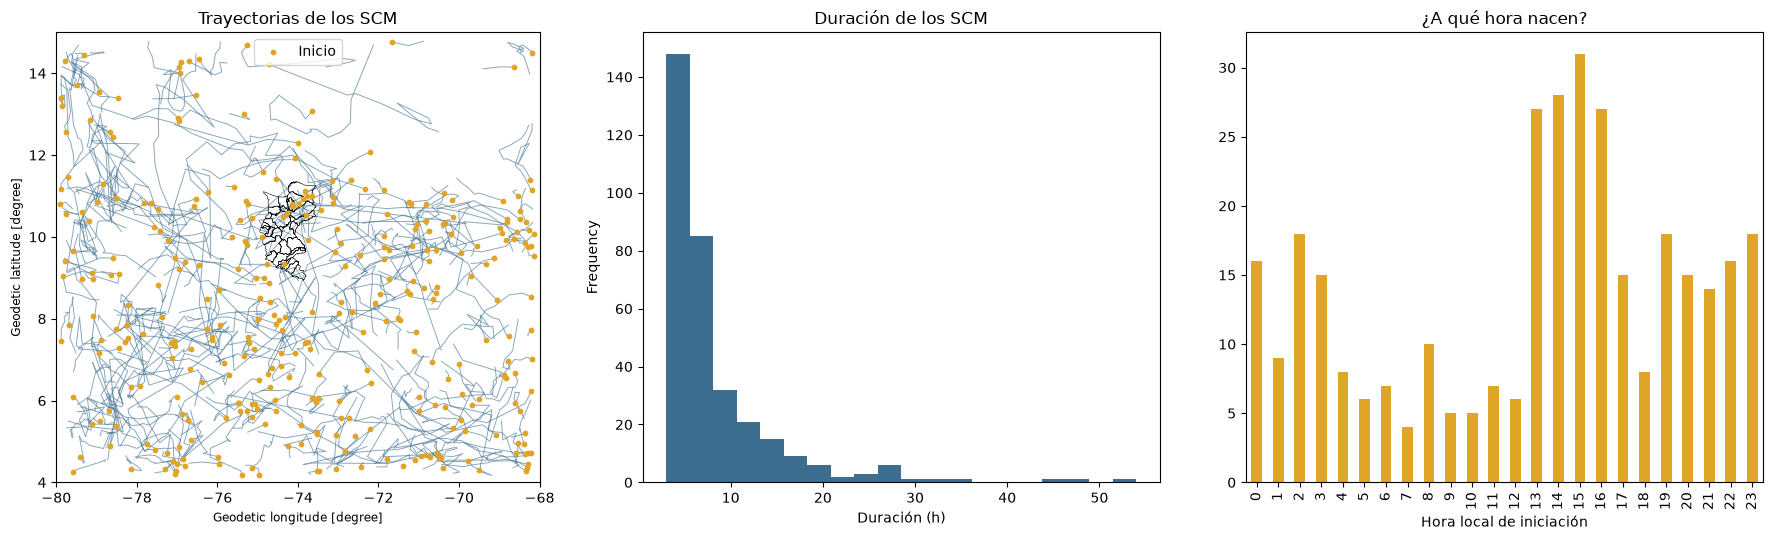

In [6]:
mpios = gpd.read_file(C.PROC / "municipios.gpkg")
inicio = df.sort_values("time").groupby("scm_id").first()
fig, axs = plt.subplots(1, 3, figsize=(18, 5.5))

# Trayectorias de los centroides
for _, s in df.groupby("scm_id"):
    axs[0].plot(s.lon_c, s.lat_c, "-", lw=0.7, alpha=0.6, color="#3D6E8F")
axs[0].scatter(inicio.lon_c, inicio.lat_c, s=10, color="#E0A526", zorder=3, label="Inicio")
mpios.boundary.plot(ax=axs[0], color="k", linewidth=0.4)
la0, la1, lo0, lo1 = C.DOM_SEGUIMIENTO
axs[0].set_xlim(lo0, lo1); axs[0].set_ylim(la0, la1); axs[0].legend()
axs[0].set_title("Trayectorias de los SCM")

# Duración
df.groupby("scm_id")["duracion_h"].first().plot.hist(ax=axs[1], bins=20, color="#3D6E8F")
axs[1].set_xlabel("Duración (h)"); axs[1].set_title("Duración de los SCM")

# Ciclo diurno de la iniciación
inicio["hora_local"].value_counts().reindex(range(24), fill_value=0).plot.bar(ax=axs[2], color="#E0A526")
axs[2].set_xlabel("Hora local de iniciación"); axs[2].set_title("¿A qué hora nacen?")
plt.tight_layout(); plt.savefig(C.OUT / "scm_descriptivos.png", dpi=150); plt.show()

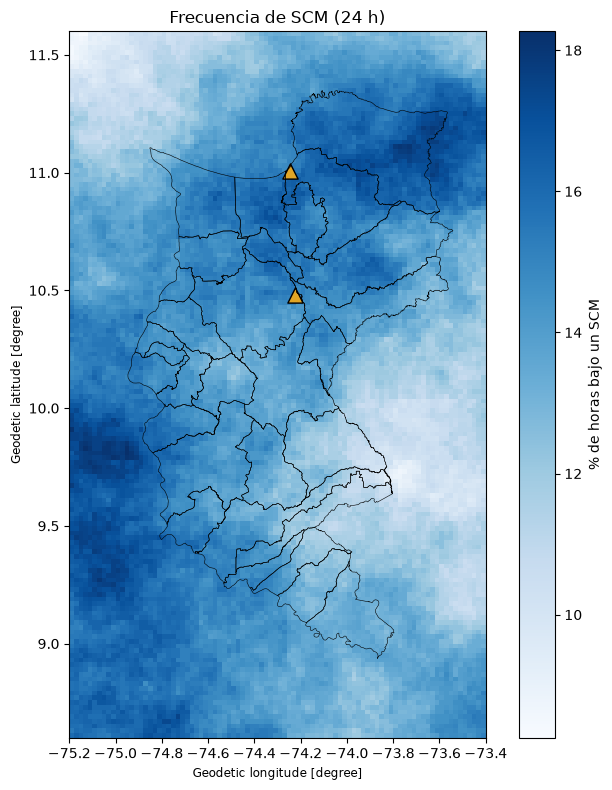

In [7]:
# Frecuencia de SCM por píxel (todas las horas) sobre el Magdalena
frec = (pila > 0).mean(axis=0)
fig, ax = plt.subplots(figsize=(7, 8))
im = ax.imshow(100 * frec, extent=[C.DOM_ANALISIS[2], C.DOM_ANALISIS[3], C.DOM_ANALISIS[0], C.DOM_ANALISIS[1]],
               cmap="Blues")
plt.colorbar(im, ax=ax, label="% de horas bajo un SCM")
mpios.boundary.plot(ax=ax, color="k", linewidth=0.4)
gpd.read_file(C.PROC / "parques.gpkg").plot(ax=ax, color="#E0A526", edgecolor="k", marker="^", markersize=120)
ax.set_title("Frecuencia de SCM (24 h)")
plt.tight_layout(); plt.savefig(C.OUT / "mapa_frecuencia_scm.png", dpi=150); plt.show()

**¿Qué revisar?** Si salen muy pocos SCM (menos de ~5 en un mes lluvioso), baja `AREA_MAX_MIN_KM2` o `DURACION_MIN_H` en `config.py`. Si salen demasiados, súbelos. Documenta el criterio que elijas.

✅ Sigue con el notebook **06**.